# Power Outages in Ukraine: Hypothesis Tests and Model

Notebook 2 of 2. It uses the cleaned dataset from notebook 1, `data/clean/hourly_dataset.csv`.

**Goals of this notebook:**
1. Test statistically the hypotheses formulated during EDA, and check whether the same weather leads to the same outcome in different seasons.
2. Build a model that estimates the probability that nationwide outages are applied in a given hour, and check what it can and cannot do.
3. Find out which factors matter most, and test the effect of solar radiation while accounting for other factors.
4. Show with scenarios how the risk is distributed over the day.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)
SEED = 42

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.family": "DejaVu Sans", "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

In [2]:
df = pd.read_csv("../data/clean/hourly_dataset.csv", parse_dates=["dt"])
# The aggregated period does not reflect the real hourly profile
df = df[df["aggregated_period"] == 0].reset_index(drop=True)
print(df.shape)
print("Share of hours with outages: {:.1%}".format(df["outage"].mean()))

(29444, 25)
Share of hours with outages: 16.7%


## 1. Statistical hypothesis tests

Neighbouring hours are very similar: if there is an outage at 18:00, there is almost certainly one at 19:00 as well. Hourly observations are therefore not independent, and standard tests on hourly data would give overly optimistic p-values. The tests are therefore run at the daily level: for each day we compute the share of hours with outages.

Even days are dependent on each other, because outage periods last for weeks. The p-values below should be treated as a guide, and the main attention should be paid to the effect size.

In [3]:
daily = df.groupby(df["dt"].dt.date).agg(
    share=("outage", "mean"),
    any_outage=("outage", "max"),
    temp=("temp_c", "mean"),
    radiation=("radiation_wm2", "mean"),
    attacks_30d=("attacks_30d", "first"),
    days_since=("days_since_attack", "first"),
    weekend=("is_weekend", "first"),
)
daily["attacked"] = (daily["attacks_30d"] > 0).astype(int)
print("Days:", len(daily))
daily.describe().round(2).T

Days: 1227


,count,mean,std,min,25%,50%,75%,max
share,1227.0,0.17,0.34,0.00,0.00,0.00,0.00,1.00
any_outage,1227.0,0.22,0.41,0.00,0.00,0.00,0.00,1.00
temp,1227.0,10.65,9.31,-18.59,2.89,10.27,18.97,29.65
radiation,1227.0,150.26,98.86,6.54,52.27,149.00,240.12,337.75
attacks_30d,1227.0,1.43,1.63,0.00,0.00,1.00,2.00,6.00
days_since,1227.0,73.59,101.44,0.00,5.00,18.00,104.50,378.00
weekend,1227.0,0.29,0.45,0.00,0.00,0.00,1.00,1.00
attacked,1227.0,0.56,0.50,0.00,0.00,1.00,1.00,1.00


**Hypothesis 1. Attacks in the previous 30 days are associated with outages.** Chi-square test for the table "attacks yes/no × outages on that day yes/no".

In [4]:
ct = pd.crosstab(daily["attacked"], daily["any_outage"])
ct.index = ["no attacks", "attacks"]
ct.columns = ["no outages", "outages"]
chi2, p, dof, _ = stats.chi2_contingency(ct)
n = ct.values.sum()
cramers_v = np.sqrt(chi2 / n)
print(ct, "\n")
print(f"chi2 = {chi2:.1f}, p = {p:.2e}, Cramer's V = {cramers_v:.2f}")
print("Share of days with outages, %:")
print((ct["outages"] / ct.sum(axis=1) * 100).round(1).to_string())

            no outages  outages
no attacks         534       11
attacks            429      253 

chi2 = 218.7, p = 1.77e-49, Cramer's V = 0.42
Share of days with outages, %:
no attacks     2.0
attacks       37.1


Without attacks, outages occurred on only 2% of days; after attacks, on 37%. A Cramér's V of 0.42 indicates a strong association for this type of table. The hypothesis is supported.

**Hypothesis 2. The more days have passed since an attack, the fewer outages.** Spearman correlation between days since the last attack and the share of outage hours. It requires only a monotonic relationship, not a linear one.

In [5]:
rho, p = stats.spearmanr(daily["days_since"], daily["share"])
print(f"Spearman: rho = {rho:.2f}, p = {p:.2e}")
near = daily[daily["days_since"] <= 60]
rho60, p60 = stats.spearmanr(near["days_since"], near["share"])
print(f"Only days within 60 days after an attack: rho = {rho60:.2f}, p = {p60:.2e}")

Spearman: rho = -0.45, p = 7.14e-62
Only days within 60 days after an attack: rho = -0.29, p = 1.07e-16


The relationship is moderate and negative: the more days have passed since an attack, the fewer outages. Within the 60-day window it is weaker, because there the weather also has a strong influence on outages.

**Hypothesis 3. After attacks, there are more outages in cold weather than in mild weather.** Among days with attacks in the previous 30 days, cold days with a mean temperature below 0 °C are compared with mild days from 5 to 20 °C. The Mann–Whitney test does not require a normal distribution.

In [6]:
att = daily[daily["attacked"] == 1]
cold = att.loc[att["temp"] < 0, "share"]
mild = att.loc[att["temp"].between(5, 20), "share"]
hot = att.loc[att["temp"] > 22, "share"]
u, p = stats.mannwhitneyu(cold, mild, alternative="greater")
print(f"Cold days: n = {len(cold)}, mean share of outage hours {cold.mean():.1%}")
print(f"Mild days: n = {len(mild)}, mean share {mild.mean():.1%}")
print(f"Mann–Whitney, cold > mild: U = {u:.0f}, p = {p:.2e}")
u2, p2 = stats.mannwhitneyu(hot, mild, alternative="greater")
print(f"\nHot days: n = {len(hot)}, mean share {hot.mean():.1%}")
print(f"Mann–Whitney, hot > mild: U = {u2:.0f}, p = {p2:.2e}")

Cold days: n = 116, mean share of outage hours 52.8%
Mild days: n = 324, mean share 13.3%
Mann–Whitney, cold > mild: U = 27392, p = 1.54e-19

Hot days: n = 66, mean share 49.6%
Mann–Whitney, hot > mild: U = 14802, p = 6.46e-11


After attacks, outages were applied on average in 53% of hours on cold days, 50% on hot days and only 13% in mild weather. Both differences are statistically significant. Section "Same weather, different seasons" below checks what stands behind these averages.

**Hypothesis 4. There are fewer outages on weekends than on weekdays.** Only days with attacks in the previous 30 days are compared, because without attacks there are almost no outages regardless of the day of week.

In [7]:
wk = att.loc[att["weekend"] == 1, "share"]
wd = att.loc[att["weekend"] == 0, "share"]
u, p = stats.mannwhitneyu(wd, wk, alternative="greater")
print(f"Weekdays: {wd.mean():.1%}, weekends: {wk.mean():.1%}, Mann–Whitney p = {p:.3f}")

Weekdays: 30.7%, weekends: 25.9%, Mann–Whitney p = 0.115


There are slightly fewer outages on weekends, 26% of hours against 31% on weekdays, but at the daily level this difference is not statistically significant, p = 0.12. The hypothesis is not supported.

**Attacks: a necessary but not a sufficient condition.** The tests above show that without attacks there are almost no outages. But do attacks always lead to outages? Below is a summary by quarter.

In [8]:
q = df.groupby(df["dt"].dt.to_period("Q")).agg(
    attacks=("attack_day", lambda s: int(s.sum() / 24)),
    mean_fired_30d=("fired_30d", "mean"),
    outage_hours_pct=("outage", "mean"),
    mean_temp_c=("temp_c", "mean"),
)
q["outage_hours_pct"] = (q["outage_hours_pct"] * 100).round(1)
q.round(0)

,attacks,mean_fired_30d,outage_hours_pct,mean_temp_c
dt,,,,
2023Q1,5,163.0,42.0,1.0
2023Q2,0,7.0,0.0,15.0
2023Q3,0,0.0,0.0,21.0
2023Q4,0,0.0,0.0,5.0
2024Q1,2,20.0,0.0,1.0
2024Q2,6,166.0,28.0,16.0
2024Q3,1,91.0,40.0,22.0
2024Q4,4,203.0,20.0,4.0
2025Q1,5,352.0,0.0,2.0


The answer is no. In the first and third quarters of 2025 there were five massive attacks each, but not a single hour of planned outages. In the second quarter of 2026 there were eight attacks, the most powerful in the whole period, and outages were applied in only 2.5% of hours. The absolute number of missiles and drones grew more than tenfold over the years, so it cannot be compared directly between years.

**Same weather, different seasons.** Mild weather does not explain the quiet quarters: the first quarter of 2025 was as cold as the first quarter of 2023. The next two tables take only days with attacks in the previous 30 days and compare the same weather in different quarters: first cold days with a mean temperature below 0 °C, then hot days above 22 °C.

In [9]:
def by_quarter(d):
    d = d.assign(quarter=pd.PeriodIndex(pd.to_datetime(d.index), freq="Q"))
    return d.groupby("quarter").agg(days=("share", "size"),
                                    outage_hours_pct=("share", lambda s: s.mean() * 100),
                                    mean_temp_c=("temp", "mean")).round(1)

# Cold days after attacks
by_quarter(att[att["temp"] < 0])

,days,outage_hours_pct,mean_temp_c
quarter,,,
2023Q1,39,67.4,-2.6
2024Q4,19,52.2,-2.0
2025Q1,33,0.0,-4.5
2026Q1,25,100.0,-8.2


In [10]:
# Hot days after attacks
by_quarter(att[att["temp"] > 22])

,days,outage_hours_pct,mean_temp_c
quarter,,,
2024Q2,6,87.5,23.5
2024Q3,30,90.8,25.1
2025Q3,15,0.0,23.6
2026Q2,15,1.4,24.1


The same weather after attacks led to opposite outcomes. On cold days outages covered 67% of hours in Q1 2023, 52% in Q4 2024 and 100% in Q1 2026, but 0% in Q1 2025, although those 33 days were colder on average, −4.5 °C, than the cold days of 2023 and 2024. On hot days the share was about 90% in summer 2024 and 0–1% in Q3 2025 and Q2 2026.

The averages of Hypothesis 3, 53% on cold days and 50% on hot days, are therefore averages over seasons of two kinds: almost everything or nothing. Weather amplifies outages in a season when the power system is short of capacity, but it does not decide whether a series of attacks turns into outages. That depends on the state of the system: what was damaged, how fast it was repaired and how much could be imported. These factors are not in the data.

For the same reason the 116 cold days and 66 hot days are not independent observations. Each group comes from only four quarters, so the p-values of Hypothesis 3 overstate the strength of the evidence.

## 2. Outage probability model

### 2.1. Features

The model only receives features that do not depend on the outages themselves: hour, day of week, weather and attack history. Net import and the number of queues are not used. Imports grow at the same time as outages as a response to the same deficit, and the number of queues is known only once outages have already been applied. Both features would leak information from the target into the features.

Two reservations about "known in advance". The attack features of a day are the same for all its 24 hours, because the register gives no time of day; in the hours before the strike itself they are not yet known. This concerns the 56 attack days, 4.6% of hours. And the weather is observed weather, not a forecast.

Models:
- **Attack history only.** A logistic regression with three features: number of attacks in 30 days, days since the last attack and the indicator of any attack in 30 days. It is a baseline that shows how much weather and hour of day add.
- **Logistic regression.** A simple model whose coefficients can be explained. To describe the U-shape, temperature is split into two features: degrees below 10 °C and degrees above 20 °C. Interactions of weather with the feature "attacks in the previous 30 days" are also added, because EDA showed that weather matters only after attacks.
- **Gradient boosting.** A more complex model that finds non-linear relationships and interactions between factors on its own. It also receives the numbers of weapons fired and not shot down in 30 days. A second version without these two features shows how much it depends on them.

In [11]:
def add_lr_features(d):
    """Derived features for logistic regression, computed from the base columns."""
    d = d.copy()
    d["cold_deg"] = (10 - d["temp_c"]).clip(lower=0)
    d["heat_deg"] = (d["temp_c"] - 20).clip(lower=0)
    d["log_days_since"] = np.log1p(d["days_since_attack"])
    d["recent_attacks"] = (d["attacks_30d"] > 0).astype(int)
    d["cold_x_recent"] = d["cold_deg"] * d["recent_attacks"]
    d["heat_x_recent"] = d["heat_deg"] * d["recent_attacks"]
    d["sun_x_recent"] = d["radiation_wm2"] * d["recent_attacks"]
    return d

df = add_lr_features(df)

NUM_LR = ["cold_deg", "heat_deg", "radiation_wm2", "cloud_pct", "wind_kmh", "is_weekend",
          "log_days_since", "attacks_30d", "recent_attacks",
          "cold_x_recent", "heat_x_recent", "sun_x_recent"]
ATTACK_ONLY = ["attacks_30d", "log_days_since", "recent_attacks"]
FEAT_GB = ["hour", "dow", "temp_c", "radiation_wm2", "cloud_pct", "wind_kmh",
           "days_since_attack", "attacks_7d", "attacks_30d", "fired_30d", "not_down_30d"]
FEAT_GB_NO_WEAPONS = [c for c in FEAT_GB if c not in ("fired_30d", "not_down_30d")]

def make_logreg(num=NUM_LR, hour=True):
    parts = [("num", StandardScaler(), num)]
    if hour:
        parts.append(("hour", OneHotEncoder(drop="first"), ["hour"]))
    return Pipeline([("prep", ColumnTransformer(parts)),
                     ("model", LogisticRegression(max_iter=3000))])

def make_gb():
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_depth=4,
                                          min_samples_leaf=200, l2_regularization=1.0,
                                          random_state=SEED)

X_LR, X_GB = NUM_LR + ["hour"], FEAT_GB

# name -> (model factory, feature list)
MODELS = {
    "attack history only": (lambda: make_logreg(ATTACK_ONLY, hour=False), ATTACK_ONLY),
    "logistic regression": (make_logreg, X_LR),
    "gradient boosting": (make_gb, FEAT_GB),
    "gradient boosting, no weapon counts": (make_gb, FEAT_GB_NO_WEAPONS),
}

def predict_all(train, test):
    """Fit every model on train and return its probabilities for test."""
    preds = {"base rate": np.full(len(test), train["outage"].mean())}
    for name, (make, cols) in MODELS.items():
        preds[name] = make().fit(train[cols], train["outage"]).predict_proba(test[cols])[:, 1]
    return preds

### 2.2. Validation on a new season

The train/test split is based on time, not random. A random split would mix neighbouring hours between the sets, and the model would effectively see the answers. The models are trained on data up to 30.09.2025 and tested on the 2025/26 season, which imitates the real situation: forecasting a new season from past ones.

Metrics:
- **ROC AUC** shows how well the model separates hours with outages from hours without them. 0.5 means guessing, 1 means perfect separation.
- **PR AUC** evaluates quality for the "outage" class specifically; it should be compared with the share of outages in the test set.
- **Brier score** shows the accuracy of the probabilities themselves; lower is better.
- **Mean probability** is compared with the observed share of outages to check whether the model underestimates the risk.

In [12]:
SPLIT = "2025-10-01"
train, test = df[df["dt"] < SPLIT], df[df["dt"] >= SPLIT]
y_tr, y_te = train["outage"], test["outage"]
print(f"Train: {len(train)} hours, outages in {y_tr.mean():.1%}")
print(f"Test:  {len(test)} hours, outages in {y_te.mean():.1%}")

preds = predict_all(train, test)
logreg = make_logreg().fit(train[X_LR], y_tr)   # kept for the importance analysis below

metrics = pd.DataFrame([{
    "model": name,
    "ROC AUC": roc_auc_score(y_te, p) if p.std() > 0 else 0.5,
    "PR AUC": average_precision_score(y_te, p),
    "Brier": brier_score_loss(y_te, p),
    "mean probability": p.mean(),
    "observed share": y_te.mean(),
} for name, p in preds.items()]).set_index("model").round(3)
metrics

Train: 24093 hours, outages in 11.8%
Test:  5351 hours, outages in 38.7%


,ROC AUC,PR AUC,Brier,mean probability,observed share
model,,,,,
base rate,0.500,0.387,0.309,0.118,0.387
attack history only,0.813,0.674,0.193,0.381,0.387
logistic regression,0.826,0.680,0.174,0.364,0.387
gradient boosting,0.862,0.823,0.263,0.100,0.387
"gradient boosting, no weapon counts",0.636,0.454,0.291,0.223,0.387


All models rank hours better than the base rate. Gradient boosting ranks best, ROC AUC 0.86 against 0.83 for logistic regression, but it strongly underestimates the risk: its mean predicted probability is 10% while the observed share is 39%. Its ranking depends on the numbers of weapons: without them its ROC AUC falls to 0.64.

The baseline with attack history only reaches ROC AUC 0.81. On this season weather and hour of day therefore add little to the ranking, 0.83 against 0.81, and improve mainly the Brier score, 0.174 against 0.193.

The mean probability of logistic regression, 36%, is close to the observed 39%. The calibration check after the ROC curves shows whether this means that its probabilities are accurate.

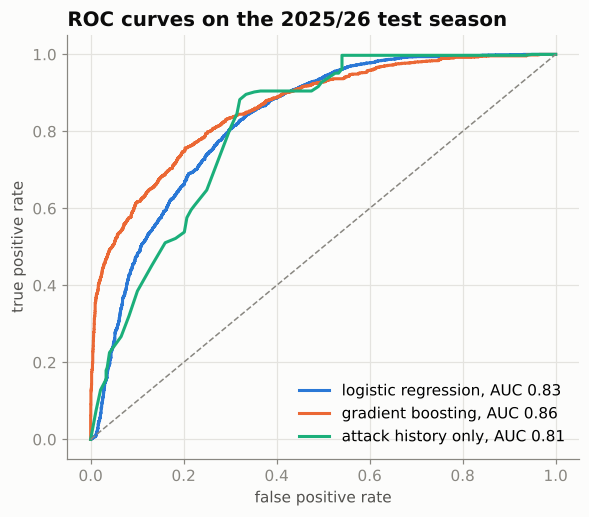

In [13]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, color in [("logistic regression", BLUE), ("gradient boosting", ORANGE), ("attack history only", AQUA)]:
    fpr, tpr, _ = roc_curve(y_te, preds[name])
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{name}, AUC {metrics.loc[name, 'ROC AUC']:.2f}")
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
ax.set_title("ROC curves on the 2025/26 test season")
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.legend(frameon=False, loc="lower right")
save(fig, "11_roc_curves")
plt.show()

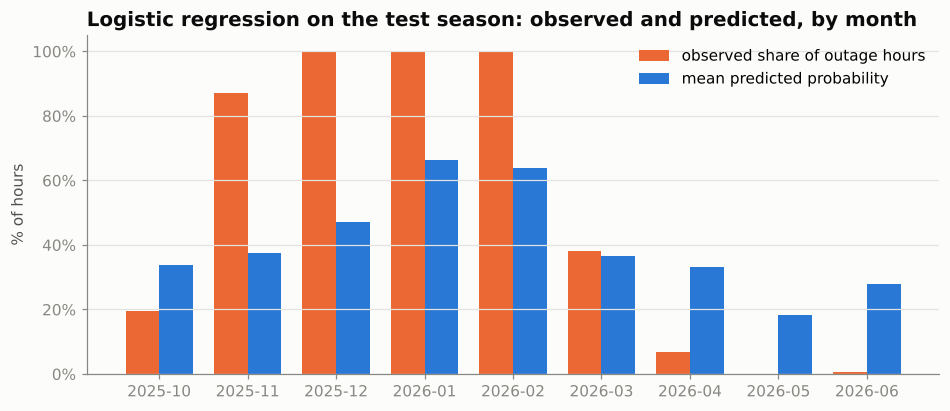

,hours,observed_pct,predicted_pct
dt,,,
2025-10,744,19.5,33.7
2025-11,720,87.1,37.5
2025-12,216,100.0,47.1
2026-01,72,100.0,66.4
2026-02,672,100.0,63.7
2026-03,743,38.2,36.7
2026-04,720,6.9,33.0
2026-05,744,0.0,18.3
2026-06,720,0.7,27.8


In [14]:
# Calibration of logistic regression on the test season, by month
cal = test.assign(p=preds["logistic regression"])
by_month = cal.groupby(cal["dt"].dt.to_period("M")).agg(
    hours=("outage", "size"), observed_pct=("outage", "mean"), predicted_pct=("p", "mean"))
by_month[["observed_pct", "predicted_pct"]] *= 100

fig, ax = plt.subplots(figsize=(10, 4))
xs = np.arange(len(by_month)); w = 0.38
ax.bar(xs - w / 2, by_month["observed_pct"], w, color=ORANGE, label="observed share of outage hours")
ax.bar(xs + w / 2, by_month["predicted_pct"], w, color=BLUE, label="mean predicted probability")
ax.set_xticks(xs)
ax.set_xticklabels(by_month.index.astype(str))
ax.set_title("Logistic regression on the test season: observed and predicted, by month")
ax.set_ylabel("% of hours")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
save(fig, "16_calibration_by_month")
plt.show()
by_month.round(1)

The probabilities are not accurate. The close mean is the result of errors that cancel each other out. The model underestimates the crisis months, 37% predicted against 87% observed in November 2025 and 64% against 100% in February 2026, and overestimates the quiet spring, 33% against 7% in April and 18% against 0% in May 2026. December 2025 and January 2026 contain only the hours outside the aggregated period.

The model orders hours by risk reasonably well, but its probabilities cannot be read as absolute values.

A single test season may be atypical, so a cross-validation by waves is also carried out: the model is trained on three periods in turn and tested on the fourth, which it has not seen. The fourth wave coincides with the test season above.

In [15]:
waves = pd.cut(df["dt"], pd.to_datetime(["2023-01-01", "2023-10-01", "2024-10-01", "2025-10-01", "2026-07-01"]),
               right=False,
               labels=["W1: 01-09.2023", "W2: 10.2023-09.2024", "W3: 10.2024-09.2025", "W4: 10.2025-06.2026"])
cv_rows = []
for w in waves.cat.categories:
    tr, te = df[waves != w], df[waves == w]
    p = predict_all(tr, te)
    y = te["outage"]
    cv_rows.append({"test wave": w, "hours": len(te), "outage share": y.mean(),
                    "AUC attacks only": roc_auc_score(y, p["attack history only"]),
                    "AUC logistic": roc_auc_score(y, p["logistic regression"]),
                    "AUC boosting": roc_auc_score(y, p["gradient boosting"]),
                    "AUC boosting, no weapons": roc_auc_score(y, p["gradient boosting, no weapon counts"]),
                    "mean p logistic": p["logistic regression"].mean(),
                    "Brier logistic": brier_score_loss(y, p["logistic regression"]),
                    "Brier base rate": brier_score_loss(y, p["base rate"])})
cv = pd.DataFrame(cv_rows).set_index("test wave")
cv.loc["mean"] = cv.mean()
cv.loc["mean", "hours"] = np.nan
cv.round(3)

,hours,outage share,AUC attacks only,AUC logistic,AUC boosting,"AUC boosting, no weapons",mean p logistic,Brier logistic,Brier base rate
test wave,,,,,,,,,
W1: 01-09.2023,6551.0,0.137,0.939,0.956,0.973,0.949,0.113,0.069,0.120
W2: 10.2023-09.2024,8783.0,0.171,0.824,0.752,0.684,0.409,0.009,0.169,0.142
W3: 10.2024-09.2025,8759.0,0.051,0.763,0.896,0.786,0.821,0.230,0.107,0.076
W4: 10.2025-06.2026,5351.0,0.387,0.813,0.826,0.862,0.636,0.364,0.174,0.309
mean,NaN,0.187,0.835,0.857,0.826,0.704,0.179,0.130,0.162


On average over the four waves logistic regression ranks hours best, AUC 0.86 against 0.83 for gradient boosting and 0.83 for the baseline with attack history only. Without the numbers of weapons gradient boosting falls to 0.70. Wave W2 with summer 2024 is the hardest: mass summer outages appeared then for the first time. On W2 the attack-only baseline, 0.82, is better than both full models, so the weather relationships learned from the other periods did not transfer to that summer.

The last three columns show that the level of risk does not transfer between waves either. For W2 logistic regression predicts a mean probability of 1% against the observed 17%, for W3 23% against 5%, and in both waves its Brier score is worse than that of the base rate.

Logistic regression is used below because of its better average ranking and because it can be interpreted. It is used to compare conditions with each other, not to state absolute probabilities.

### 2.3. What drives outages: odds ratios

For interpretation, logistic regression is trained on all data. An odds ratio above 1 means that the factor increases the odds of an outage, with the other features unchanged.

Because of the interactions, the effect of weather after attacks is the sum of two coefficients: the main effect and the interaction with recent attacks. Read separately, they are misleading. Per standard deviation the interaction "cold × recent attacks" has an odds ratio of 13.5 and cold alone 0.09. The second number is estimated on 5,187 hours without recent attacks and below 10 °C, among which there was not a single outage hour. It only cancels the interaction where there were no attacks.

The odds ratios below are therefore given in natural units and, for weather, for hours after recent attacks. The intervals are 95% intervals from a block bootstrap: whole calendar months are resampled with replacement and the model is refitted 300 times. Months are used as blocks because outage periods last for weeks and neighbouring hours are not independent.

The last row is a robustness check for the sun. Radiation follows a regular daily and seasonal cycle, so its coefficient may partly reflect the season. In the check, radiation is replaced by its deviation from the usual value for that month and hour, that is by how sunny the hour was compared with the norm. Cloud cover is left out of this check because it measures the same thing.

Hours without recent attacks and below 10 °C: 5187, outage hours among them: 0
Odds ratios per standard deviation:
cold_deg           0.09
heat_deg           1.98
radiation_wm2      0.39
cloud_pct          1.12
wind_kmh           1.04
is_weekend         0.84
log_days_since     0.82
attacks_30d        2.62
recent_attacks     1.74
cold_x_recent     13.46
heat_x_recent      1.33
sun_x_recent       0.94


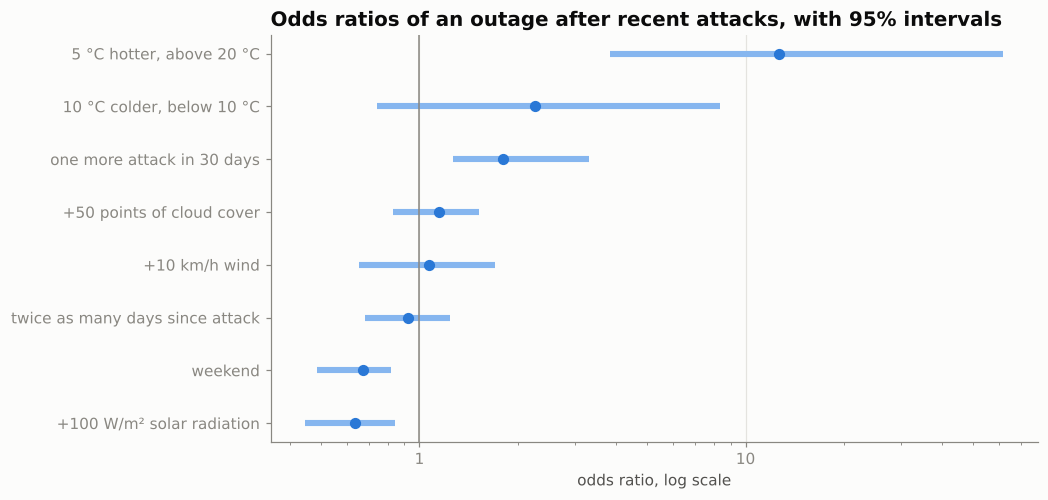

,odds ratio,2.5%,97.5%
"10 °C colder, below 10 °C",2.26,0.74,8.35
"5 °C hotter, above 20 °C",12.68,3.83,61.57
one more attack in 30 days,1.80,1.27,3.31
+100 W/m² solar radiation,0.64,0.45,0.84
twice as many days since attack,0.92,0.68,1.24
weekend,0.67,0.48,0.82
+50 points of cloud cover,1.15,0.83,1.53
+10 km/h wind,1.07,0.65,1.70
check: +100 W/m² above the norm for month and hour,0.83,0.72,0.95


In [16]:
logreg_full = make_logreg().fit(df[X_LR], df["outage"])

# Coefficients per standard deviation, for reference only (see the text above)
per_sd = pd.Series(np.exp(logreg_full.named_steps["model"].coef_[0][:len(NUM_LR)]), index=NUM_LR)
no_att_cold = df[(df["attacks_30d"] == 0) & (df["cold_deg"] > 0)]
print(f"Hours without recent attacks and below 10 °C: {len(no_att_cold)}, outage hours among them: {no_att_cold['outage'].sum()}")
print("Odds ratios per standard deviation:")
print(per_sd.round(2).to_string())

# Radiation as a deviation from its usual value for the month and hour
df["rad_anom"] = df["radiation_wm2"] - df.groupby([df["dt"].dt.month, "hour"])["radiation_wm2"].transform("mean")
df["anom_x_recent"] = df["rad_anom"] * df["recent_attacks"]
NUM_ANOM = [c for c in NUM_LR if c not in ("radiation_wm2", "sun_x_recent", "cloud_pct")] + ["rad_anom", "anom_x_recent"]

def raw_betas(model, num):
    """Coefficients per one natural unit of each numeric feature."""
    scale = model.named_steps["prep"].named_transformers_["num"].scale_
    return dict(zip(num, model.named_steps["model"].coef_[0][:len(num)] / scale))

def effects(d):
    """Odds ratios for interpretable changes; weather effects are for hours after recent attacks."""
    b = raw_betas(make_logreg().fit(d[X_LR], d["outage"]), NUM_LR)
    ba = raw_betas(make_logreg(NUM_ANOM).fit(d[NUM_ANOM + ["hour"]], d["outage"]), NUM_ANOM)
    return {
        "10 °C colder, below 10 °C": np.exp(10 * (b["cold_deg"] + b["cold_x_recent"])),
        "5 °C hotter, above 20 °C": np.exp(5 * (b["heat_deg"] + b["heat_x_recent"])),
        "one more attack in 30 days": np.exp(b["attacks_30d"]),
        "+100 W/m² solar radiation": np.exp(100 * (b["radiation_wm2"] + b["sun_x_recent"])),
        "twice as many days since attack": np.exp(np.log(2) * b["log_days_since"]),
        "weekend": np.exp(b["is_weekend"]),
        "+50 points of cloud cover": np.exp(50 * b["cloud_pct"]),
        "+10 km/h wind": np.exp(10 * b["wind_kmh"]),
        "check: +100 W/m² above the norm for month and hour": np.exp(100 * (ba["rad_anom"] + ba["anom_x_recent"])),
    }

point = effects(df)

N_BOOT = 300
month_blocks = [g for _, g in df.groupby(df["dt"].dt.to_period("M"))]
rng = np.random.default_rng(SEED)
boot = pd.DataFrame([
    effects(pd.concat([month_blocks[i] for i in rng.choice(len(month_blocks), len(month_blocks))], ignore_index=True))
    for _ in range(N_BOOT)])
odds = pd.DataFrame({"odds ratio": pd.Series(point),
                     "2.5%": boot.quantile(0.025), "97.5%": boot.quantile(0.975)})

shown = odds.iloc[:-1].sort_values("odds ratio")
fig, ax = plt.subplots(figsize=(9, 4.8))
ys = np.arange(len(shown))
ax.hlines(ys, shown["2.5%"], shown["97.5%"], color="#86b6ef", lw=4)
ax.scatter(shown["odds ratio"], ys, color=BLUE, s=40, zorder=3)
ax.axvline(1, color=MUTED, lw=1)
ax.set_xscale("log")
ax.set_yticks(ys)
ax.set_yticklabels(shown.index)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_title("Odds ratios of an outage after recent attacks, with 95% intervals")
ax.set_xlabel("odds ratio, log scale")
ax.grid(axis="y", visible=False)
save(fig, "12_logreg_odds_ratios")
plt.show()
odds.round(2)

After recent attacks:
- **Heat** has the largest effect: 5 °C above 20 °C multiply the odds by 12.7, interval 3.8–62. The estimate rests mostly on one summer, 2024.
- **Cold:** 10 °C below 10 °C multiply the odds by 2.3, but the interval, 0.7–8.4, includes 1. This agrees with the comparison of seasons above: in Q1 2025 frost after attacks caused no outages.
- **Each additional attack** in 30 days multiplies the odds by 1.8, interval 1.3–3.3.
- **Solar radiation:** 100 W/m² more multiply the odds by 0.64, interval 0.45–0.84. In the robustness check the effect keeps its direction but is less than half as strong: 0.83, interval 0.72–0.95. The data are consistent with a contribution of solar generation, which could not be seen in the simple grouping in EDA. They do not prove it, because the actual output of solar plants is not observed.
- **Weekend:** odds ratio 0.67, interval 0.48–0.82, although the daily test of Hypothesis 4 was not significant. The evidence on weekends is mixed.
- Time since the last attack, cloud cover and wind have intervals that include 1.

The intervals should be read as approximate. The main variation is between seasons, and there are only a few seasons with outages, so even month blocks may understate the uncertainty.

### 2.4. Importance of feature groups

Permutation importance shows how much the ROC AUC of logistic regression on the test season drops when the values of features are shuffled at random. Features are grouped by meaning, because several attack features carry similar information and would individually understate each other's importance. After shuffling, derived features such as interactions are recomputed.

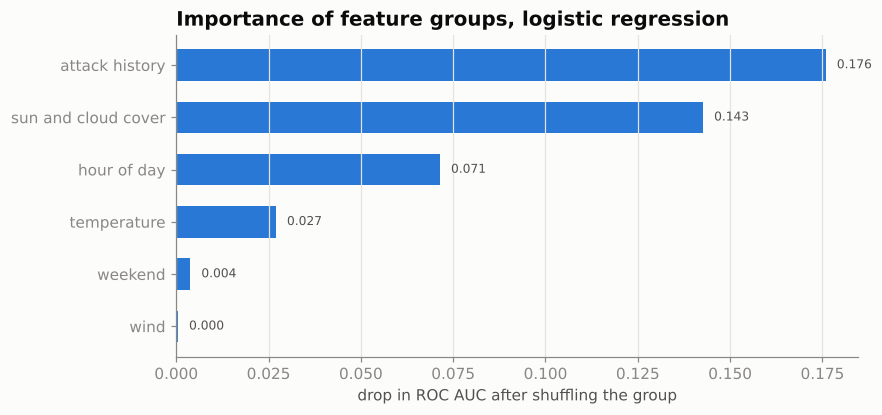

attack history         0.176
sun and cloud cover    0.143
hour of day            0.071
temperature            0.027
weekend                0.004
wind                   0.000
dtype: float64

In [17]:
groups = {
    "attack history": ["days_since_attack", "attacks_30d"],
    "temperature": ["temp_c"],
    "hour of day": ["hour"],
    "weekend": ["is_weekend"],
    "sun and cloud cover": ["radiation_wm2", "cloud_pct"],
    "wind": ["wind_kmh"],
}
rng = np.random.default_rng(SEED)
base = test.reset_index(drop=True)
base_auc = roc_auc_score(y_te, logreg.predict_proba(base[X_LR])[:, 1])
imp = {}
for g, cols in groups.items():
    drops = []
    for _ in range(5):
        Xp = base.copy()
        Xp[cols] = Xp[cols].values[rng.permutation(len(Xp))]   # shuffle the group together
        Xp = add_lr_features(Xp)
        drops.append(base_auc - roc_auc_score(y_te, logreg.predict_proba(Xp[X_LR])[:, 1]))
    imp[g] = np.mean(drops)
imp = pd.Series(imp).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(imp.index, imp.values, color=BLUE, height=0.6)
ax.set_title("Importance of feature groups, logistic regression")
ax.set_xlabel("drop in ROC AUC after shuffling the group")
ax.grid(axis="y", visible=False)
for i, v in enumerate(imp.values):
    ax.text(max(v, 0) + 0.003, i, f"{v:.3f}", va="center", fontsize=8, color=INK2)
save(fig, "13_feature_importance")
plt.show()
imp.sort_values(ascending=False).round(3)

The most important group is attack history, followed by sun and cloud cover, and then hour of day. Temperature has low importance here because the test season fell almost entirely in cold months, and shuffling temperature within it changes little. The effect of temperature is visible from the coefficients above and the charts below.

### 2.5. How the probability depends on temperature and sun

Partial dependence plots use logistic regression trained on all data. The chart shows the mean probability of an outage when one feature is varied and the others are kept as in the real data. The calculation uses hours with attacks in the previous 30 days, because outside them the probability is almost zero.

Only temperature and solar radiation are shown. Hour of day cannot be varied meaningfully while radiation stays fixed, and time since the last attack has almost no effect in the model once the number of attacks is fixed.

Temperature: minimum 18.3%, at -15 °C 52.3%, at 33 °C 98.2%
Radiation: 39.5% without sun, 3.9% at 850 W/m²


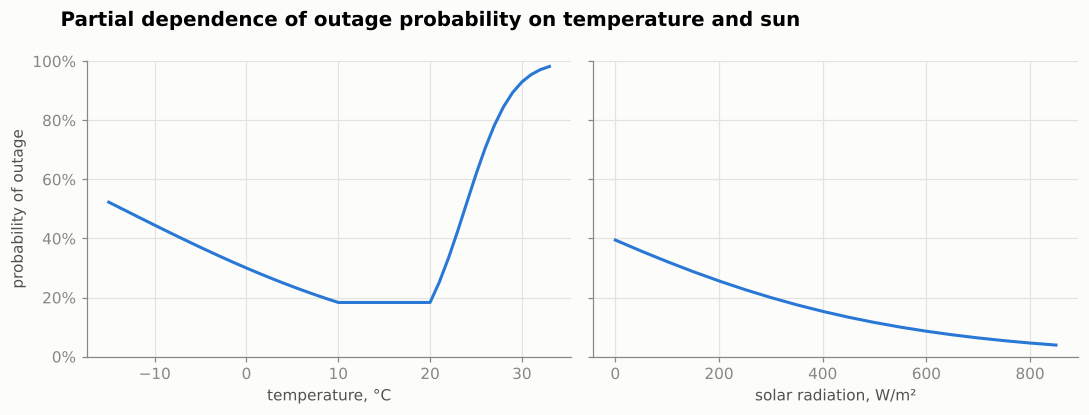

In [18]:
def predict_lr(d):
    d = add_lr_features(d)
    return logreg_full.predict_proba(d[X_LR])[:, 1]

def partial_dependence(X, feature, grid):
    out = []
    for v in grid:
        Xv = X.copy()
        Xv[feature] = v
        out.append(predict_lr(Xv).mean())
    return np.array(out)

ref = df[df["attacks_30d"] > 0].sample(4000, random_state=SEED)
pd_specs = [
    ("temp_c", np.arange(-15, 34, 1), "temperature, °C"),
    ("radiation_wm2", np.arange(0, 851, 50), "solar radiation, W/m²"),
]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
pd_values = {}
for ax, (feat, grid, label) in zip(axes, pd_specs):
    pd_values[feat] = pd.Series(partial_dependence(ref, feat, grid) * 100, index=grid)
    ax.plot(grid, pd_values[feat], color=BLUE, lw=2)
    ax.set_xlabel(label)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
axes[0].set_ylabel("probability of outage")
axes[0].set_ylim(0, 100)
fig.suptitle("Partial dependence of outage probability on temperature and sun",
             x=0.06, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "14_partial_dependence")
plt.show()
print("Temperature: minimum {:.1f}%, at -15 °C {:.1f}%, at 33 °C {:.1f}%".format(
    pd_values["temp_c"].min(), pd_values["temp_c"].iloc[0], pd_values["temp_c"].iloc[-1]))
print("Radiation: {:.1f}% without sun, {:.1f}% at 850 W/m²".format(
    pd_values["radiation_wm2"].iloc[0], pd_values["radiation_wm2"].iloc[-1]))

How to read the charts:
- **Temperature:** the curve is U-shaped. The risk is lowest, 18%, from 10 to 20 °C, rises gradually with frost to 52% at −15 °C and sharply above 22 °C. Values above 30 °C should be treated with caution: there are few such hours and almost all of them belong to one summer.
- **Sun:** the stronger the radiation, the lower the probability, from 40% without sun to 4% at 850 W/m². The reservations about the solar effect from section 2.3 apply here as well.

Both curves are averages over seasons with very different outcomes. They show the direction and shape of the relationship, not the level to expect in a particular season.

## 3. Scenarios: how the risk is distributed over the day

The model can show how the risk changes during the day under different conditions. Below are four scenarios; for each, the probability of an outage is calculated for every hour of a working day. Each scenario sets the mean daily temperature, while its daily course, solar radiation and cloud cover for every hour are taken as the averages for the corresponding month from the real data.

Two things should be kept in mind when reading them:
- The target is whether nationwide outages were applied in a given hour, not whether a particular consumer was disconnected. Outages rotate between queues, so the chance that a specific home or business is without power in that hour is lower.
- The levels are averages over seasons. Section 2.2 showed that absolute probabilities do not transfer from one season to another. The scenarios are meant for comparing hours and conditions with each other.

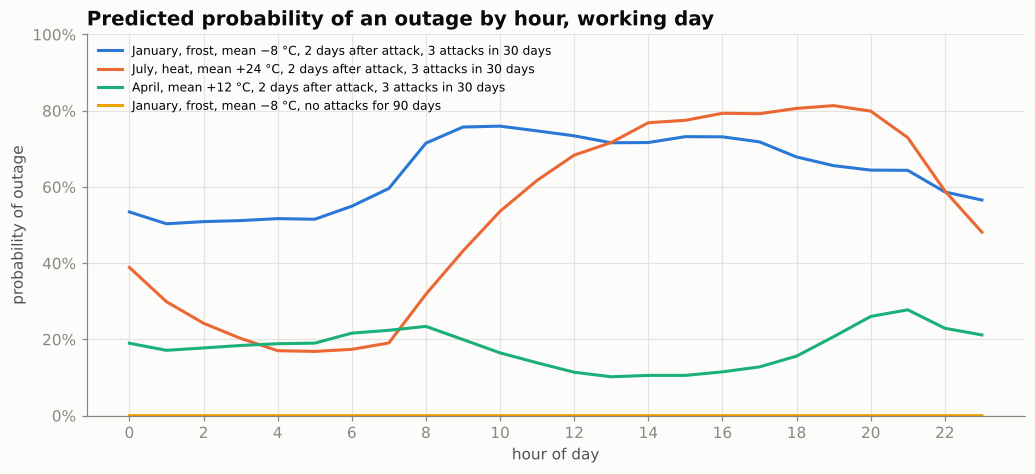

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
"January, frost, mean −8 °C, 2 days after attack, 3 attacks in 30 days",53.0,50.0,51.0,51.0,52.0,52.0,55.0,60.0,71.0,76.0,76.0,75.0,73.0,72.0,72.0,73.0,73.0,72.0,68.0,66.0,64.0,64.0,59.0,57.0
"July, heat, mean +24 °C, 2 days after attack, 3 attacks in 30 days",39.0,30.0,24.0,20.0,17.0,17.0,17.0,19.0,32.0,43.0,54.0,62.0,68.0,72.0,77.0,77.0,79.0,79.0,81.0,81.0,80.0,73.0,59.0,48.0
"April, mean +12 °C, 2 days after attack, 3 attacks in 30 days",19.0,17.0,18.0,18.0,19.0,19.0,22.0,22.0,23.0,20.0,16.0,14.0,11.0,10.0,11.0,11.0,11.0,13.0,16.0,21.0,26.0,28.0,23.0,21.0
"January, frost, mean −8 °C, no attacks for 90 days",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [19]:
month = df["dt"].dt.month
rad_profile = df.groupby([month, "hour"])["radiation_wm2"].mean()
cloud_profile = df.groupby([month, "hour"])["cloud_pct"].mean()
# daily course of temperature: deviation of each hour from the daily mean, averaged by month
temp_anom = (df["temp_c"] - df.groupby(df["dt"].dt.date)["temp_c"].transform("mean")).groupby([month, df["hour"]]).mean()

def scenario(m, temp, days_since, attacks_30d, weekend=0):
    s = pd.DataFrame({"hour": range(24)})
    s["is_weekend"] = weekend
    s["temp_c"] = temp + temp_anom.loc[m].values   # temp = mean daily temperature
    s["radiation_wm2"] = rad_profile.loc[m].values
    s["cloud_pct"] = cloud_profile.loc[m].values
    s["wind_kmh"] = df["wind_kmh"].median()
    s["days_since_attack"] = days_since
    s["attacks_30d"] = attacks_30d
    return predict_lr(s)

scen = pd.DataFrame({
    "January, frost, mean −8 °C, 2 days after attack, 3 attacks in 30 days": scenario(1, -8, 2, 3),
    "July, heat, mean +24 °C, 2 days after attack, 3 attacks in 30 days": scenario(7, 24, 2, 3),
    "April, mean +12 °C, 2 days after attack, 3 attacks in 30 days": scenario(4, 12, 2, 3),
    "January, frost, mean −8 °C, no attacks for 90 days": scenario(1, -8, 90, 0),
})

fig, ax = plt.subplots(figsize=(11, 4.5))
for (name, col), color in zip(scen.items(), [BLUE, ORANGE, AQUA, YELLOW]):
    ax.plot(scen.index, col * 100, color=color, lw=2, label=name)
ax.set_title("Predicted probability of an outage by hour, working day")
ax.set_xlabel("hour of day")
ax.set_ylabel("probability of outage")
ax.set_xticks(range(0, 24, 2))
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.legend(frameon=False, loc="upper left", fontsize=8)
save(fig, "15_business_scenarios")
plt.show()
(scen * 100).round(0).T

What the scenarios show:
- **Winter after attacks:** the risk is high around the clock, from 50% at night to 76% at 09:00–10:00. There is no safe part of the day.
- **Summer heat after attacks:** the risk is lowest before dawn, about 17%, and rises steeply during the day to 81% at 18:00–19:00, when the heat persists while the sun is already weakening.
- **Spring after attacks:** the risk is moderate, lowest around 13:00 at 10% and highest in the evening at 28% at 21:00.
- **Frost without attacks:** the risk is practically zero.

For planning, the shape of the curves is more reliable than their level: in winter after attacks no hours are safe, in summer the evening is the riskiest part of the day, in spring midday is the safest.

## 4. Conclusions

1. **Massive attacks are a precondition for outages.** Without massive attacks in the previous 30 days, outages occurred on only 2% of days; after attacks, on 37%. No outage occurred later than 60 days after an attack.
2. **Attacks are not a sufficient condition.** In Q1 and Q3 2025 and in Q2 2026 the power system withstood series of attacks almost without outages.
3. **Weather amplifies outages but does not decide them.** After attacks, outages were applied on average in 53% of hours on cold days, 50% on hot days and 13% in mild weather. These averages hide opposite seasons: cold days after attacks had 0% of outage hours in Q1 2025 and 100% in Q1 2026, hot days about 90% in summer 2024 and 0–1% in 2025 and 2026. What decides is the state of the power system, which is not in the data.
4. **Effects in the model.** After attacks, 5 °C of heat above 20 °C multiply the odds of an outage by 12.7, and each additional attack in 30 days by 1.8. The effect of cold, 2.3 per 10 °C, has an interval that includes 1.
5. **The sun is associated with lower risk.** 100 W/m² more radiation multiply the odds by 0.64, and by 0.83 when radiation is measured against its norm for the month and hour. This is consistent with a contribution of solar generation but does not prove it.
6. **The difference between weekdays and weekends is not established:** the daily test is not significant, the model gives an odds ratio of 0.67.
7. **The model ranks, it does not predict levels.** Logistic regression separates hours with and without outages with ROC AUC 0.83 on the 2025/26 season, which it had not seen, and 0.86 on average over four waves. A baseline with attack history only reaches 0.81 and 0.83. The mean predicted probability, 36% against the observed 39%, hides large errors by month, and in two of the four waves the Brier score is worse than the base rate.

**Limitations:**
- Hours and days are strongly dependent on each other, and outages come in a few seasons, so p-values and intervals should be treated as a guide.
- Round-the-clock days contain 70% of outage hours, so the hourly target mostly reflects differences between days and seasons.
- The attack data contain only massive strikes without the time of day, and weather in Kyiv is used as a proxy for the whole country.
- The model does not account for the state of repairs, import capacity and fuel stocks, which are not available as open data. These factors probably explain why the same attacks and the same weather led to outages in one season and not in another.
- Probabilities for very hot hours above 30 °C are unreliable because of the small number of such observations.

**Practical value:** the analysis shows which conditions and which hours are riskier than others after a massive attack. It should not be used as a forecast of the probability that a particular consumer loses power.